# 04 · Q1 — ดัชนีเดี่ยวตัวไหนอธิบายระดับน้ำทะเลอันดามันได้ ที่คาบไหน ช่วงปีไหน

## สายงานต่อหนึ่งคู่ (สถานี, ดัชนี)

## การตัดสินใจที่เปเปอร์ต้นทางไม่ได้บอก (ต้องประกาศในรายงาน)

| เรื่อง | ที่เลือก | เหตุผล |
| --- | --- | --- |
| threshold | เปอร์เซ็นไทล์ 95 **แยกรายสเกล** จาก 1000 surrogate · รวมเฉพาะจุดในกรวย | threshold เป็นรูปตัว U ตามสเกล (หัวข้อ 1) ค่าเดียวทั้งระนาบจะให้สองปลายมีนัยสำคัญมั่ว |
| AR(1) | lag-1 autocorrelation เฉพาะคู่จุดที่เป็นข้อมูลจริงทั้งคู่ | ช่องว่างที่ interp เป็นเส้นตรงดัน a ขึ้น |
| พื้นที่ที่นับ | ในกรวย COI และของเติมในหน้าต่าง S_time ≤ 50% · นับ pixel = นับบนแกน log | |
| **p-value ของ PASC** | เทียบกับ PASC ของ surrogate อีก 1000 คู่ (ชุดใหม่) | **PASC รายแถบของ noise ล้วนสูงถึง ~22% ได้** — เทียบกับ 5% ตรง ๆ ไม่ได้ |
| ทดสอบหลายครั้ง | Benjamini–Hochberg บน 24 การทดสอบของสถานีหลัก | 8 ดัชนี × 3 แถบ ที่ α = 0.05 คาดว่าจะผ่านโดยบังเอิญ ~1.2 ตัว |

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from wtc.coherence import wtc
from wtc.metrics import BANDS, pasc, significance, summarize, valid_mask
from wtc.transform import cwt, DJ, DT_MONTHLY
from wtc.plotting import use_thai_font, plot_coherence, period_axis

FIGURES = ROOT / "figures"; FIGURES.mkdir(exist_ok=True)
use_thai_font()

r = np.load(ROOT / "data" / "processed" / "wtc_q1.npz", allow_pickle=True)
stations = [str(s) for s in r["stations"]]; indices = [str(s) for s in r["indices"]]
bands = [str(s) for s in r["bands"]]
t, periods, coi, scales = r["t"], r["periods"], r["coi"], r["scales"]
summary = json.loads(str(r["summary"])); meta = json.loads(str(r["meta"]))
MAIN = stations[0]
LABEL = {"ko_taphao_noi": "KO TAPHAO NOI (อันดามัน)", "ko_lak": "KO LAK (อ่าวไทย)",
         "fort_phrachula_chomklao": "FORT PHRACHULA (อ่าวไทยตอนบน)"}
NAME = {"nino34": "Niño3.4", "soi": "SOI", "pdo": "PDO", "amo": "AMO", "nao": "NAO",
        "tpi": "TPI", "dmi": "DMI (IOD)", "wnpmi": "WNPMI (มรสุม)"}
print(f"สถานีหลัก {MAIN} · {len(stations)} สถานี × {len(indices)} ดัชนี · surrogate {meta['nmc']} ชุด/คู่ · seed {meta['seed']}")
assert MAIN == "ko_taphao_noi" and meta["nmc"] >= 1000

สถานีหลัก ko_taphao_noi · 3 สถานี × 8 ดัชนี · surrogate 1000 ชุด/คู่ · seed 20260930


## 1. threshold รายสเกล — ทำไมใช้ค่าเดียวทั้งระนาบไม่ได้

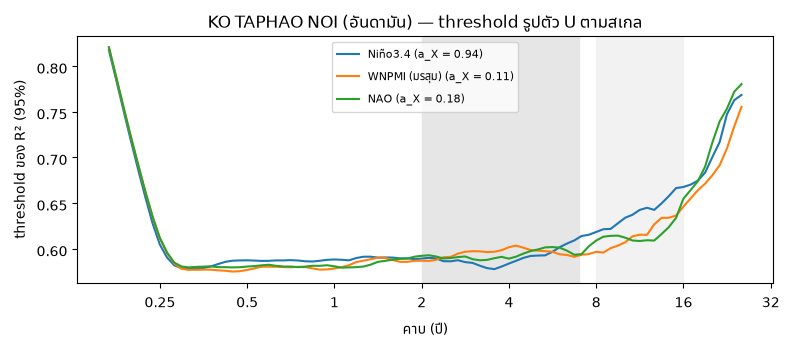

Niño3.4: ช่วงกลาง ≈ 0.590 · คาบสั้นสุด 0.818 · คาบยาวสุดที่ยังมีจุดในกรวย 0.768


In [2]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, c in (("nino34", "C0"), ("wnpmi", "C1"), ("nao", "C2")):
    j = indices.index(k)
    ax.plot(periods, r["threshold"][0, j], color=c,
            label=f"{NAME[k]} (a_X = {r['a_x'][0, j]:.2f})")
ax.set_xscale("log", base=2)
ticks = [v for v in (0.25, 0.5, 1, 2, 4, 8, 16, 32) if periods.min() <= v <= periods.max()]
ax.set_xticks(ticks); ax.set_xticklabels([f"{v:g}" for v in ticks]); ax.minorticks_off()
ax.axvspan(2, 7, color="0.9", zorder=0); ax.axvspan(8, 16, color="0.95", zorder=0)
ax.set_xlabel("คาบ (ปี)"); ax.set_ylabel("threshold ของ R² (95%)")
ax.set_title(f"{LABEL[MAIN]} — threshold รูปตัว U ตามสเกล"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES / "w4-threshold-per-scale.png", dpi=130); plt.show()

th = r["threshold"][0, indices.index("nino34")]
mid = np.nanmedian(th[(periods > 1) & (periods < 8)])
print(f"Niño3.4: ช่วงกลาง ≈ {mid:.3f} · คาบสั้นสุด {th[0]:.3f} · คาบยาวสุดที่ยังมีจุดในกรวย {th[np.isfinite(th)][-1]:.3f}")

## 2. ผลหลัก — KO TAPHAO NOI × 8 ดัชนี

In [3]:
def bh_qvalues(p):
    p = np.asarray(p, float); m = len(p); order = np.argsort(p)
    q = p[order] * m / np.arange(1, m + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty(m); out[order] = np.minimum(q, 1.0)
    return out

S = summary[MAIN]
pvals = np.array([S[k][b]["p"] for k in indices for b in bands])
qvals = bh_qvalues(pvals).reshape(len(indices), len(bands))

order = sorted(indices, key=lambda k: -S[k]["ทั้งระนาบ"]["pasc"])
hdr = " │ ".join(f"{b:^31s}" for b in bands)
print(f"{'ดัชนี':15s} │ {hdr}")
print(f"{'':15s} │ " + " │ ".join(f"{'PASC%':>7s} {'p':>6s} {'q(BH)':>6s} {'null95':>6s} {'AWC':>4s}" for _ in bands))
for k in order:
    j = indices.index(k); cells = []
    for bi, b in enumerate(bands):
        m = S[k][b]; mark = "**" if qvals[j, bi] < 0.05 else ("* " if m["p"] < 0.05 else "  ")
        a = f"{m['awc']:.2f}" if m["awc"] == m["awc"] else "  — "
        cells.append(f"{m['pasc']:5.1f}{mark} {m['p']:6.3f} {qvals[j, bi]:6.3f} {m['null_p95']:6.1f} {a:>4s}")
    print(f"{NAME[k]:15s} │ " + " │ ".join(cells))
print("\n*  p < 0.05 (เทียบ null ของ PASC)   ** ผ่านหลังปรับ Benjamini–Hochberg ด้วย (q < 0.05)")
print(f"ความละเอียดของ p ที่เล็กที่สุดที่รายงานได้ = 1/{meta['nmc'] + 1} ≈ {1/(meta['nmc']+1):.4f}")

ดัชนี           │            ทั้งระนาบ            │             2–7 ปี              │             8–16 ปี            
                │   PASC%      p  q(BH) null95  AWC │   PASC%      p  q(BH) null95  AWC │   PASC%      p  q(BH) null95  AWC
SOI             │  13.9**  0.002  0.016    8.8 0.71 │  15.5*   0.038  0.130   14.5 0.75 │   3.8    0.302  0.517   30.3 0.67
WNPMI (มรสุม)   │  13.5**  0.002  0.016    8.7 0.72 │  32.4**  0.001  0.016   12.9 0.73 │   0.0    1.000  1.000   26.6   — 
DMI (IOD)       │  13.2**  0.004  0.024    8.8 0.70 │  17.2*   0.026  0.104   13.6 0.71 │   0.0    1.000  1.000   28.6   — 
Niño3.4         │  10.2*   0.018  0.086    8.7 0.69 │  13.9    0.052  0.139   13.9 0.72 │   0.0    1.000  1.000   22.1   — 
AMO             │   8.2    0.078  0.187    8.9 0.70 │  14.0*   0.048  0.139   13.7 0.72 │   0.4    0.422  0.632   28.1 0.62
TPI             │   7.0    0.176  0.352    9.0 0.68 │  10.8    0.114  0.248   14.0 0.69 │   0.0    1.000  1.000   29.9   — 
NAO           

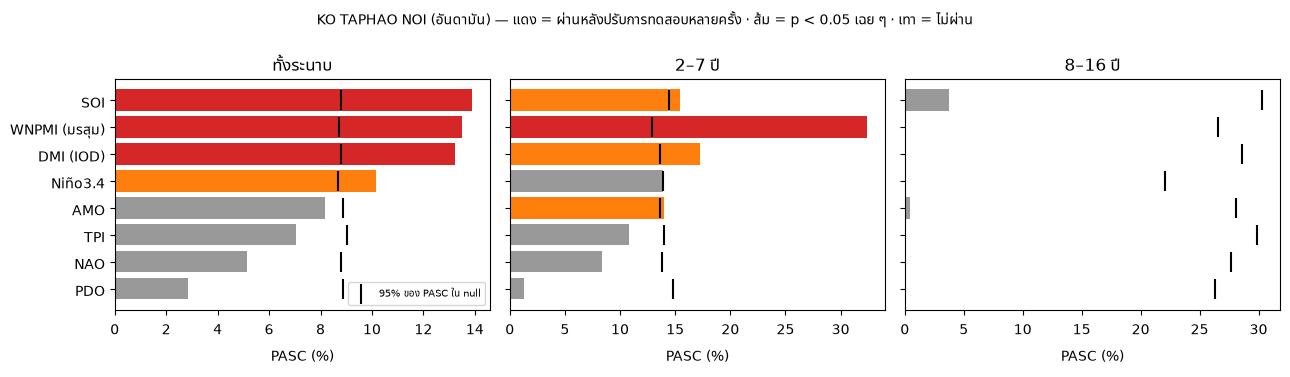

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, b in zip(axes, bands):
    y = np.arange(len(order))
    obs = [S[k][b]["pasc"] for k in order]
    p95 = [S[k][b]["null_p95"] for k in order]
    colors = ["C3" if qvals[indices.index(k), bands.index(b)] < 0.05 else
              ("C1" if S[k][b]["p"] < 0.05 else "0.6") for k in order]
    ax.barh(y, obs, color=colors)
    ax.scatter(p95, y, marker="|", s=200, color="k", zorder=3, label="95% ของ PASC ใน null")
    ax.set_title(b); ax.set_xlabel("PASC (%)"); ax.invert_yaxis()
axes[0].set_yticks(np.arange(len(order))); axes[0].set_yticklabels([NAME[k] for k in order])
axes[0].legend(fontsize=7, loc="lower right")
fig.suptitle(f"{LABEL[MAIN]} — แดง = ผ่านหลังปรับการทดสอบหลายครั้ง · ส้ม = p < 0.05 เฉย ๆ · เทา = ไม่ผ่าน",
             fontsize=10)
fig.tight_layout(); fig.savefig(FIGURES / "w4-q1-pasc-bars.png", dpi=130); plt.show()

## 3. ระนาบ coherence ทั้ง 8 ดัชนี

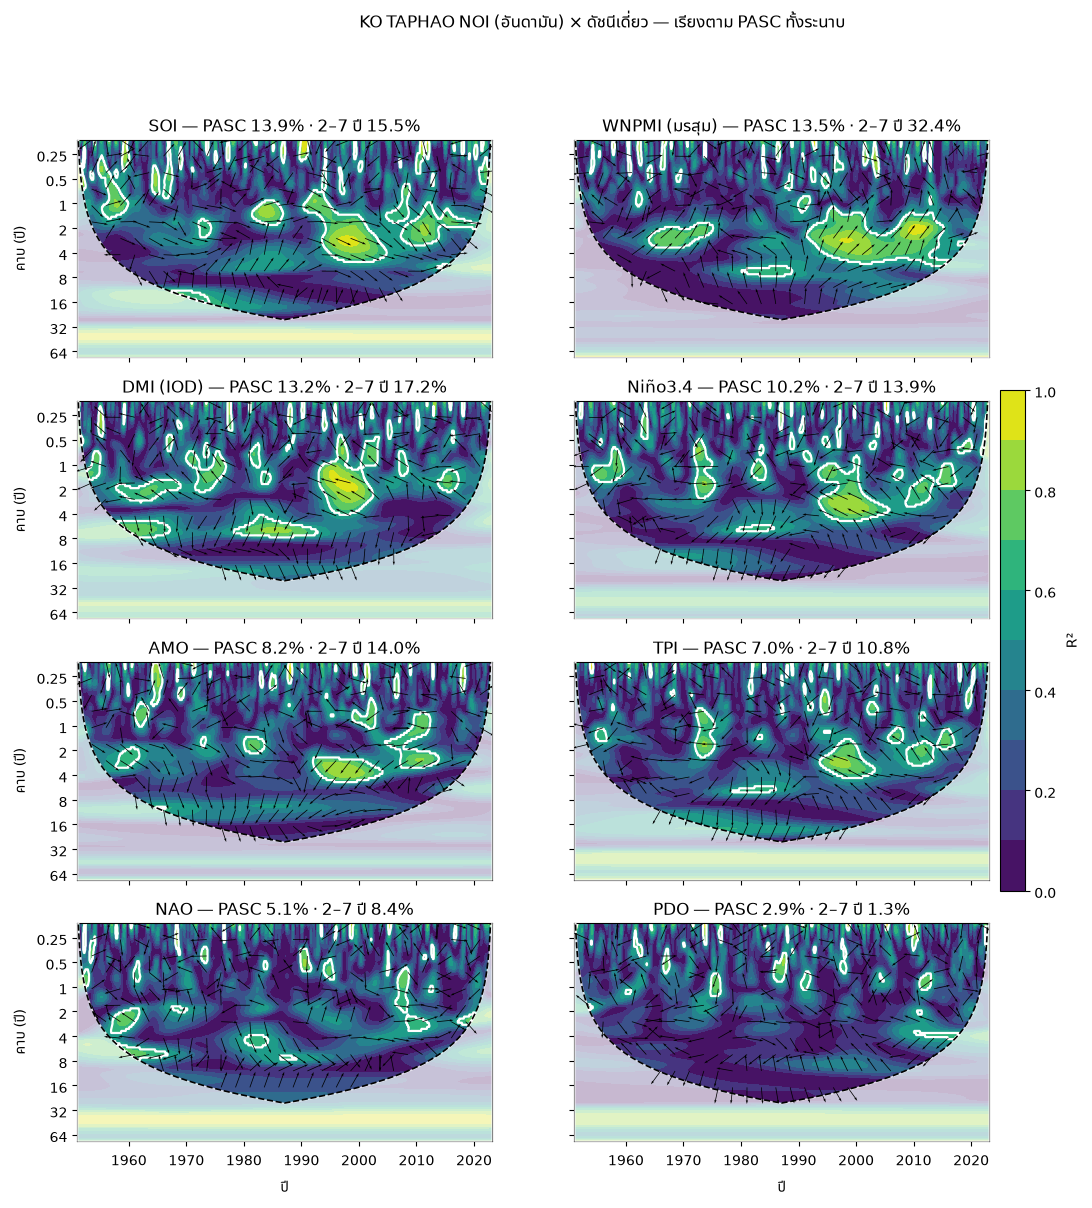

In [5]:
fig, axes = plt.subplots(4, 2, figsize=(14, 13), sharex=True, sharey=True)
for ax, k in zip(axes.ravel(), order):
    j = indices.index(k)
    R2 = r["R2"][0, j].astype(float); ph = r["phase"][0, j].astype(float)
    sigv = r["sig"][0, j] & r["valid"][0, j]
    cf = plot_coherence(ax, t, periods, R2, coi, phase=ph, sig_mask=sigv, arrow_step=(8, 30),
                        title=f"{NAME[k]} — PASC {S[k]['ทั้งระนาบ']['pasc']:.1f}% · "
                              f"2–7 ปี {S[k]['2–7 ปี']['pasc']:.1f}%")
    ax.label_outer()
fig.colorbar(cf, ax=axes, shrink=0.5, pad=0.01, label="R²")
fig.suptitle(f"{LABEL[MAIN]} × ดัชนีเดี่ยว — เรียงตาม PASC ทั้งระนาบ", fontsize=12)
fig.savefig(FIGURES / "w4-q1-coherence-8.png", dpi=110, bbox_inches="tight"); plt.show()

## 4. ทำไม PASC ต้องมี p-value ของตัวเอง — ดูการกระจายของ null

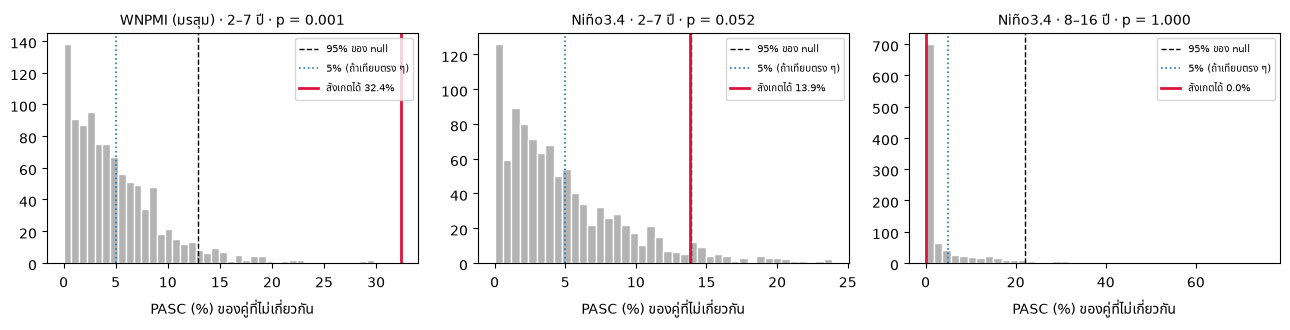

แถบ 8–16 ปี: null ของทุกดัชนี — สัดส่วนที่ PASC = 0 พอดี 56% · 95% อยู่ที่ 28%


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, (k, b) in zip(axes, (("wnpmi", "2–7 ปี"), ("nino34", "2–7 ปี"), ("nino34", "8–16 ปี"))):
    j, bi = indices.index(k), bands.index(b)
    null = r["null"][0, j, bi]
    ax.hist(null, bins=40, color="0.7", edgecolor="w")
    ax.axvline(np.percentile(null, 95), color="k", ls="--", lw=1, label="95% ของ null")
    ax.axvline(5, color="C0", ls=":", lw=1.2, label="5% (ถ้าเทียบตรง ๆ)")
    ax.axvline(S[k][b]["pasc"], color="crimson", lw=2, label=f"สังเกตได้ {S[k][b]['pasc']:.1f}%")
    ax.set_title(f"{NAME[k]} · {b} · p = {S[k][b]['p']:.3f}", fontsize=10)
    ax.set_xlabel("PASC (%) ของคู่ที่ไม่เกี่ยวกัน"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIGURES / "w4-q1-pasc-null.png", dpi=130); plt.show()

nb = r["null"][0, :, bands.index("8–16 ปี")]
print(f"แถบ 8–16 ปี: null ของทุกดัชนี — สัดส่วนที่ PASC = 0 พอดี {np.mean(nb == 0):.0%} · "
      f"95% อยู่ที่ {np.percentile(nb, 95):.0f}%")

## 5. ตรวจความสอดคล้องเชิงกายภาพ (เกณฑ์ proposal §4)

เหตุการณ์ในหน้าต่าง: El Niño 153 เดือน · La Niña 248 เดือน · ปกติ 464 เดือน
สัดส่วนของแถบ 2–7 ปีที่มีนัยสำคัญ (KO TAPHAO NOI × Niño3.4)
   ช่วงที่มีเหตุการณ์ ENSO  15.3%
   ช่วงปกติ               10.5%


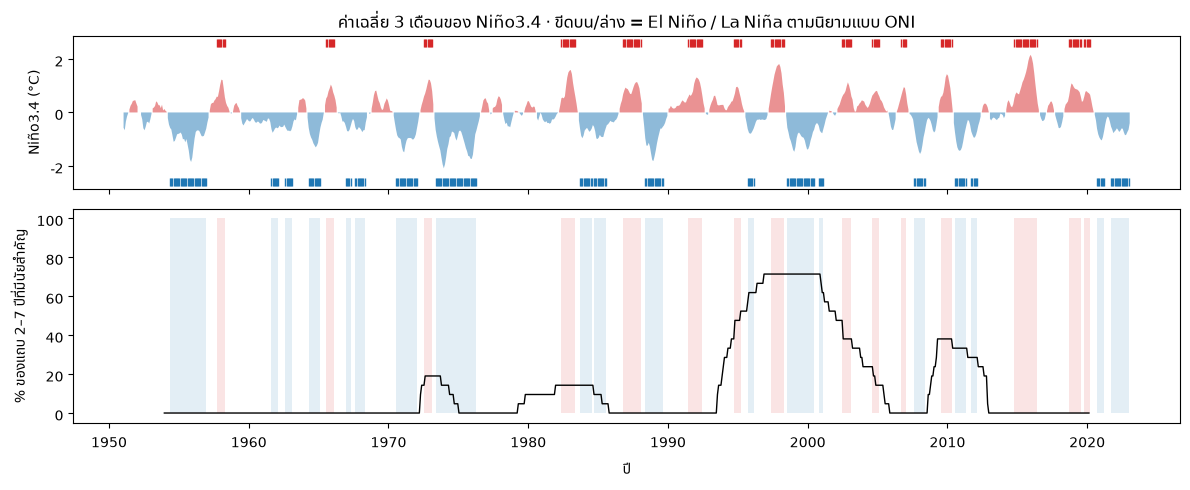

In [7]:
from wtc.loaders import read_noaa_index
from wtc.preprocess import align
tn, vn = read_noaa_index(ROOT / "data" / "raw" / "indices" / "nino34.data")
_, al = align({"nino34": (tn, vn)}, float(t[0]) - 1/24, float(t[-1]) + 1/24)
anom = al["nino34"]
assert len(anom) == len(t) and np.isfinite(anom).all()
oni = np.convolve(anom, np.ones(3) / 3, mode="same")

def events(cond, min_len=5):
    out = np.zeros(len(cond), bool)
    e = np.flatnonzero(np.diff(np.r_[0, cond.astype(np.int8), 0]))
    for a, b in zip(e[::2], e[1::2]):
        if b - a >= min_len: out[a:b] = True
    return out

nino, nina = events(oni >= 0.5), events(oni <= -0.5)
j = indices.index("nino34")
rows = (periods >= 2) & (periods <= 7)
sig_b = (r["sig"][0, j] & r["valid"][0, j])[rows]
val_b = r["valid"][0, j][rows]
has_val = val_b.any(axis=0)
frac = np.where(has_val, sig_b.sum(axis=0) / np.maximum(val_b.sum(axis=0), 1), np.nan)

m_event = np.nanmean(frac[(nino | nina) & has_val]); m_neutral = np.nanmean(frac[~(nino | nina) & has_val])
print(f"เหตุการณ์ในหน้าต่าง: El Niño {nino.sum()} เดือน · La Niña {nina.sum()} เดือน · ปกติ {(~(nino|nina)).sum()} เดือน")
print(f"สัดส่วนของแถบ 2–7 ปีที่มีนัยสำคัญ (KO TAPHAO NOI × Niño3.4)")
print(f"   ช่วงที่มีเหตุการณ์ ENSO  {m_event:.1%}")
print(f"   ช่วงปกติ               {m_neutral:.1%}")

fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
ax[0].fill_between(t, 0, oni, where=oni > 0, color="C3", alpha=0.5, lw=0)
ax[0].fill_between(t, 0, oni, where=oni < 0, color="C0", alpha=0.5, lw=0)
ax[0].plot(t[nino], np.full(nino.sum(), 2.6), "|", color="C3", ms=6)
ax[0].plot(t[nina], np.full(nina.sum(), -2.6), "|", color="C0", ms=6)
ax[0].set_ylabel("Niño3.4 (°C)"); ax[0].set_title("ค่าเฉลี่ย 3 เดือนของ Niño3.4 · ขีดบน/ล่าง = El Niño / La Niña ตามนิยามแบบ ONI")
ax[1].plot(t, 100 * frac, color="k", lw=1)
for m_, c in ((nino, "C3"), (nina, "C0")):
    ax[1].fill_between(t, 0, 100, where=m_, color=c, alpha=0.12, lw=0)
ax[1].set_ylabel("% ของแถบ 2–7 ปีที่มีนัยสำคัญ"); ax[1].set_xlabel("ปี")
fig.tight_layout(); fig.savefig(FIGURES / "w4-q1-enso-consistency.png", dpi=130); plt.show()

## 6. สองสถานีสำรอง (Q2 · Q8) — คำนวณไว้แล้ว จะรายงานถ้า W6 ปิดทัน

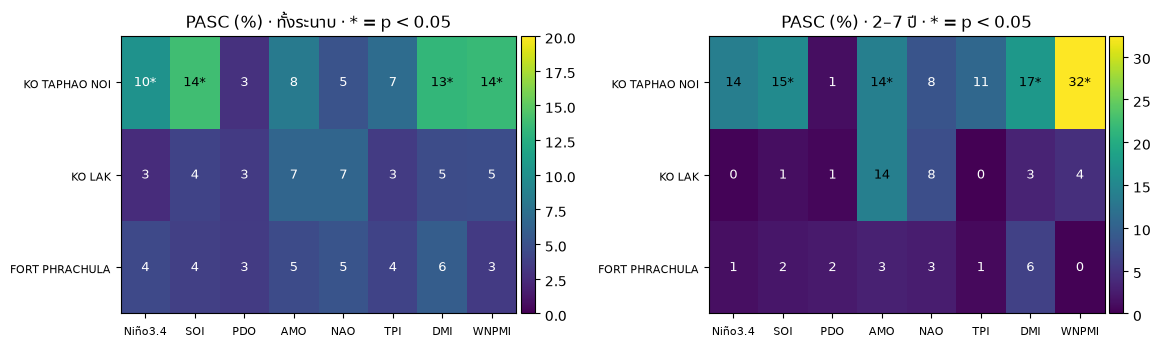

KO LAK (อ่าวไทย)                 ผ่าน p < 0.05 0 จาก 24 การทดสอบ (คาดว่าจะผ่านโดยบังเอิญ ~1.2)
FORT PHRACHULA (อ่าวไทยตอนบน)    ผ่าน p < 0.05 0 จาก 24 การทดสอบ (คาดว่าจะผ่านโดยบังเอิญ ~1.2)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, b in zip(axes, ("ทั้งระนาบ", "2–7 ปี")):
    M = np.array([[summary[s][k][b]["pasc"] for k in indices] for s in stations])
    P = np.array([[summary[s][k][b]["p"] for k in indices] for s in stations])
    im = ax.imshow(M, cmap="viridis", aspect="auto", vmin=0, vmax=max(20, np.nanmax(M)))
    for i in range(M.shape[0]):
        for j_ in range(M.shape[1]):
            ax.text(j_, i, f"{M[i, j_]:.0f}{'*' if P[i, j_] < 0.05 else ''}", ha="center", va="center",
                    color="w" if M[i, j_] < 12 else "k", fontsize=9)
    ax.set_xticks(range(len(indices))); ax.set_xticklabels([NAME[k].split(" ")[0] for k in indices], fontsize=8)
    ax.set_yticks(range(len(stations))); ax.set_yticklabels([LABEL[s].split(" (")[0] for s in stations], fontsize=8)
    ax.set_title(f"PASC (%) · {b} · * = p < 0.05")
    fig.colorbar(im, ax=ax, pad=0.01)
fig.tight_layout(); fig.savefig(FIGURES / "w4-q1-stations-heatmap.png", dpi=130); plt.show()

for s in stations[1:]:
    n_sig = sum(summary[s][k][b]["p"] < 0.05 for k in indices for b in bands)
    print(f"{LABEL[s]:32s} ผ่าน p < 0.05 {n_sig} จาก 24 การทดสอบ (คาดว่าจะผ่านโดยบังเอิญ ~1.2)")

## 7. เทียบกับเปเปอร์ต้นทาง

In [9]:
paper = {"nino34": 14.03, "tpi": 12.92, "soi": 10.86, "pdo": 9.86, "nao": 8.80, "amo": 6.07}
ours = {k: S[k]["ทั้งระนาบ"]["pasc"] for k in paper}
rp = sorted(paper, key=lambda k: -paper[k]); ro = sorted(ours, key=lambda k: -ours[k])
print(f"{'อันดับ':6s} {'Song & Chen (อเมริกาเหนือ)':28s} {'เรา (KO TAPHAO NOI)':28s}")
for i in range(6):
    print(f"{i+1:6d} {NAME[rp[i]]:14s} {paper[rp[i]]:6.2f}%       {NAME[ro[i]]:14s} {ours[ro[i]]:6.2f}%")
ranks_p = {k: rp.index(k) for k in paper}; ranks_o = {k: ro.index(k) for k in paper}
d2 = sum((ranks_p[k] - ranks_o[k]) ** 2 for k in paper)
print(f"\nSpearman ρ ระหว่างสองลำดับ = {1 - 6 * d2 / (6 * (36 - 1)):+.2f}  (6 ดัชนี — ตัวเลขเดียวจากตัวอย่างเล็ก อ่านเป็นทิศทางเท่านั้น)")
print(f"ดัชนีที่เราเพิ่มเอง: WNPMI {S['wnpmi']['ทั้งระนาบ']['pasc']:.1f}% · DMI {S['dmi']['ทั้งระนาบ']['pasc']:.1f}%")

อันดับ Song & Chen (อเมริกาเหนือ)   เรา (KO TAPHAO NOI)         
     1 Niño3.4         14.03%       SOI             13.89%
     2 TPI             12.92%       Niño3.4         10.16%
     3 SOI             10.86%       AMO              8.17%
     4 PDO              9.86%       TPI              7.04%
     5 NAO              8.80%       NAO              5.13%
     6 AMO              6.07%       PDO              2.85%

Spearman ρ ระหว่างสองลำดับ = +0.37  (6 ดัชนี — ตัวเลขเดียวจากตัวอย่างเล็ก อ่านเป็นทิศทางเท่านั้น)
ดัชนีที่เราเพิ่มเอง: WNPMI 13.5% · DMI 13.2%


## 8. ด่านตรวจ — คำนวณคู่หนึ่งใหม่ต้องได้ค่าเดียวกับสคริปต์

In [10]:
d = np.load(ROOT / "data" / "processed" / "series.npz", allow_pickle=True)
yn = [str(s) for s in d["y_names"]]; xn = [str(s) for s in d["x_names"]]
y, x = d["Y"][yn.index(MAIN)], d["X"][xn.index("wnpmi")]
Wy, sc_, per_, coi_ = cwt(y); Wx, _, _, _ = cwt(x)
R2_new, _ = wtc(Wy, Wx, DT_MONTHLY, DJ, sc_)
j = indices.index("wnpmi")
assert np.abs(R2_new - r["R2"][0, j].astype(float)).max() < 1e-6
v_new = valid_mask(per_, coi_, sc_, DT_MONTHLY, d["Y_fill"][yn.index(MAIN)], d["X_fill"][xn.index("wnpmi")])
assert np.array_equal(v_new, r["valid"][0, j])
s_new = summarize(R2_new, significance(R2_new, r["threshold"][0, j]), v_new, per_)
for b in bands:
    assert abs(s_new[b]["pasc"] - S["wnpmi"][b]["pasc"]) < 1e-9
print("✅ คำนวณ KO TAPHAO NOI × WNPMI ใหม่ในโน้ตบุ๊ก ได้ R², mask และ PASC ตรงกับ scripts/run_wtc.py")

✅ คำนวณ KO TAPHAO NOI × WNPMI ใหม่ในโน้ตบุ๊ก ได้ R², mask และ PASC ตรงกับ scripts/run_wtc.py


## สรุป Q1 — 🚦 ประตู G2

### ข้อจำกัดที่ต้องประกาศ